# Lab Day 10: Finetune Qwen3-VL-4B (LoRA) để định vị hư hại mặt đường
Notebook chạy trọn bài lab trên **Google Colab T4**. Mã nằm trong thư mục `lab/` (không sửa `scripts/`, `tests/` của đề):

| File | Việc |
|---|---|
| `lab/common.py` | nhãn YOLO→JSON 0–1000, prompt, nạp model 4-bit, `encode_example` (mask loss), `collate`, `apply_setup` (LoRA/projector), suy luận |
| `lab/run.py` | chạy 1 thí nghiệm: huấn luyện → suy luận → `scripts/score.py` (tự làm tiếp nếu Colab ngắt) |
| `lab/inspect_model.py` | đếm tham số ViT / projector / LLM và số module LoRA (252 / 348) |
| `lab/reward.py`, `lab/grpo.py`, `lab/tests/` | E5: reward IoU + test + GRPO |
| `lab/report_tools.py` | bảng tổng hợp, ảnh minh hoạ đúng/sai, đường loss |

**Lần đầu:** mở notebook này từ GitHub trong Colab → chạy mục 0 (clone repo vào Drive) → từ lần sau mở `lab_day10.ipynb` **trong thư mục repo trên Drive** để thay đổi được lưu lại.
**Mỗi phiên mới:** chạy lại mục 0 và ô đầu của mục 1 (dữ liệu ở `/content` bị xoá khi hết phiên), rồi nhảy tới bước đang làm.
Các thí nghiệm chạy bằng `!python -m lab.run ...` trong tiến trình riêng nên VRAM được giải phóng sau mỗi lần; chạy lại đúng lệnh đó sau khi bị ngắt sẽ làm tiếp từ checkpoint.

## 0. Môi trường (Colab T4)

In [11]:
!git pull
!python -m lab.run --config configs/e0.yaml --name e0 --data-dir {DATA_DIR}

remote: Enumerating objects: 4, done.
remote: Counting objects: 100% (4/4), done.
remote: Total 4 (delta 3), reused 4 (delta 3), pack-reused 0 (from 0)
Unpacking objects: 100% (4/4), 673 bytes | 7.00 KiB/s, done.
From https://github.com/Baor-AI/K4-Track-4-Day10-VisionLanguageModel
   b3546f6..b7fcf90  main       -> origin/main
Updating b3546f6..b7fcf90
Fast-forward
 lab/common.py | 9 ++++++---
 1 file changed, 6 insertions(+), 3 deletions(-)
Loading weights: 100% 713/713 [00:37<00:00, 18.95it/s]
suy luận 311 ảnh (đã có 0) -> work/e0/pred_test.jsonl
  4/311  ví dụ: '[{"label": "crack", "bbox_2d": [750, 634, 850, 684]}]'
  44/311  ví dụ: '[{"label": "pothole", "bbox_2d": [470, 596, 550, 638]}]'
  84/311  ví dụ: '[{"label": "crack", "bbox_2d": [0, 678, 1000, 750]}]'
  124/311  ví dụ: '[{"label": "pothole", "bbox_2d": [187, 557, 517, 684]}]'
  164/311  ví dụ: '[{"label": "crack", "bbox_2d": [1, 627, 1000, 750]}]'
  204/311  ví dụ: '[{"label": "crack", "bbox_2d": [280, 576, 400, 700]}]'
  2

In [1]:
# ==== BẠN ĐIỀN Ở ĐÂY ====
GITHUB_REPO = "https://github.com/Baor-AI/K4-Track-4-Day10-VisionLanguageModel"  # repo công khai của bạn
DRIVE_REPO  = "/content/drive/MyDrive/K4-Day10"   # repo + work/ (adapter, dự đoán) lưu trên Drive
DATA_DIR    = "/content/data"                     # dữ liệu ở ổ local của Colab (đọc nhanh hơn Drive)

# Tên các Secret trong Colab (biểu tượng chìa khoá bên trái). Giá trị KHÔNG ghi vào notebook.
SECRET_KAGGLE_USER = "KAGGLE_USERNAME"
SECRET_KAGGLE_KEY  = "KAGGLE_KEY"
SECRET_GH_TOKEN    = "GH_TOKEN"     # tuỳ chọn: GitHub token (quyền ghi repo) để push từ Colab
GIT_NAME  = "Nguyễn Văn Bảo"                      # tên hiển thị trong commit
GIT_EMAIL = "baour1210@gmail.com"                      # email commit

In [2]:
# Runtime → Change runtime type → T4 GPU
from google.colab import drive
drive.mount('/content/drive')
import os
if not os.path.exists(f"{DRIVE_REPO}/.git"):
    !git clone {GITHUB_REPO} "{DRIVE_REPO}"
%cd "{DRIVE_REPO}"
!git config core.fileMode false
!git pull --ff-only || echo "bỏ qua pull (có thay đổi cục bộ)"

Mounted at /content/drive
Cloning into '/content/drive/MyDrive/K4-Day10'...
remote: Enumerating objects: 47, done.
remote: Counting objects: 100% (17/17), done.
remote: Compressing objects: 100% (15/15), done.
remote: Total 47 (delta 3), reused 13 (delta 1), pack-reused 30 (from 1)
Receiving objects: 100% (47/47), 53.52 KiB | 576.00 KiB/s, done.
Resolving deltas: 100% (5/5), done.
/content/drive/MyDrive/K4-Day10
Already up to date.


In [3]:
!nvidia-smi -L
!pip -q install -r requirements-colab.txt
!pip -q uninstall -y torchao
import torch; print(torch.__version__, torch.cuda.get_device_name(0))

GPU 0: Tesla T4 (UUID: GPU-894fefb8-292e-feca-f49a-8af7f027889b)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 114.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 835.4/835.4 kB 59.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 889.0/889.0 kB 59.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 21.2 MB/s eta 0:00:00
2.11.0+cu130 Tesla T4


In [4]:
# Kaggle: dùng Colab Secrets. KHÔNG viết khoá vào notebook.
from google.colab import userdata
os.environ['KAGGLE_USERNAME'] = userdata.get(SECRET_KAGGLE_USER)
os.environ['KAGGLE_KEY'] = userdata.get(SECRET_KAGGLE_KEY)

In [5]:
# Công cụ của đề + test của bạn (không cần GPU)
!python -m pytest -q
!python -m pytest -q lab/tests

...........................s.........................................    [100%]
68 passed, 1 skipped in 1.05s
.........                                                                [100%]
9 passed in 0.19s


## 1. Dữ liệu: tải và chia split

In [6]:
# Chạy lại mỗi phiên mới. Split cố định nên lần nào cũng ra cùng dataset_version.
if not os.path.exists(f"{DATA_DIR}/splits/meta.json"):
    !python scripts/prepare_data.py --kaggle --out {DATA_DIR} --work /content/kaggle_raw
# chép splits (nhỏ) vào repo để scripts/score.py và check_submission.py đối chiếu được (data/ đã .gitignore)
!mkdir -p data && rm -rf data/splits && cp -r {DATA_DIR}/splits data/splits
import json
meta = json.load(open(f"{DATA_DIR}/splits/meta.json"))
print("dataset_version:", meta["dataset_version"])

Dataset URL: https://www.kaggle.com/datasets/lorenzoarcioni/road-damage-dataset-potholes-cracks-and-manholes
License(s): MIT
100% 185M/185M [00:01<00:00, 188MB/s]

dataset_version : d10-21e4070301
  train  1422 ảnh  boxes={'pothole': 1074, 'crack': 1750, 'manhole': 691}
  val     276 ảnh  boxes={'pothole': 66, 'crack': 470, 'manhole': 103}
  test    311 ảnh  boxes={'pothole': 121, 'crack': 299, 'manhole': 163}
dataset_version: d10-21e4070301


In [7]:
from collections import Counter
from lab.common import load_split, open_image
splits = {s: load_split(s, DATA_DIR) for s in ("train", "val", "test")}
for s, rows in splits.items():
    c = Counter(o["label"] for r in rows for o in r["objects"])
    print(f"{s:5s} {len(rows):5d} ảnh  {sum(c.values()):5d} box  {dict(c)}  "
          f"ảnh không box: {sum(1 for r in rows if not r['objects'])}  "
          f"box nhiều nhất/ảnh: {max(len(r['objects']) for r in rows)}")
sess = {s: {r["session"] for r in rows} for s, rows in splits.items()}
print("số phiên:", {s: len(v) for s, v in sess.items()})
print("phiên trùng train∩val, train∩test, val∩test:",
      len(sess["train"] & sess["val"]), len(sess["train"] & sess["test"]), len(sess["val"] & sess["test"]))

train  1422 ảnh   3515 box  {'manhole': 691, 'pothole': 1074, 'crack': 1750}  ảnh không box: 0  box nhiều nhất/ảnh: 13
val     276 ảnh    639 box  {'crack': 470, 'manhole': 103, 'pothole': 66}  ảnh không box: 0  box nhiều nhất/ảnh: 9
test    311 ảnh    583 box  {'crack': 299, 'manhole': 163, 'pothole': 121}  ảnh không box: 0  box nhiều nhất/ảnh: 7
số phiên: {'train': 13, 'val': 2, 'test': 3}
phiên trùng train∩val, train∩test, val∩test: 0 0 0


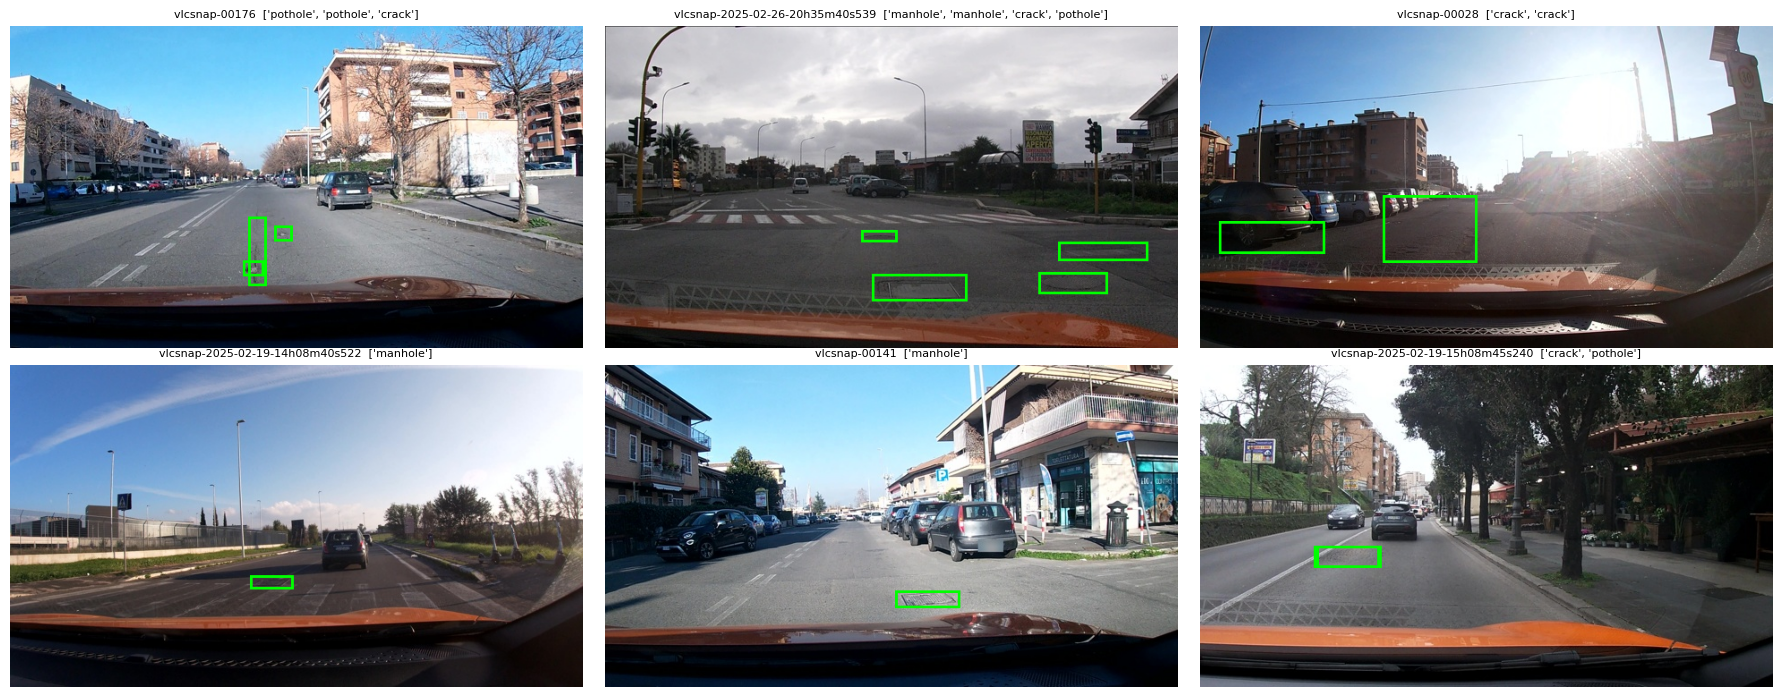

In [8]:
# Vẽ 6 ảnh train có box (xanh lá = nhãn gốc)
import matplotlib.pyplot as plt, random
from lab.report_tools import draw
sample = random.Random(1).sample([r for r in splits["train"] if r["objects"]], 6)
fig, axes = plt.subplots(2, 3, figsize=(18, 7))
for ax, e in zip(axes.flat, sample):
    ax.imshow(draw(e, [], DATA_DIR)); ax.set_title(f"{e['image_id']}  {[o['label'] for o in e['objects']]}", fontsize=8); ax.axis("off")
plt.tight_layout(); plt.show()

## 2. Nhãn: YOLO → JSON thang 0–1000

In [9]:
from lab.common import yolo_to_box, objects_to_answer, make_prompt
e = sample[0]
ans = objects_to_answer(e["objects"])
print("PROMPT:", make_prompt()); print("ANSWER:", ans)
# Kiểm tra: JSON 0–1000 -> pixel phải trùng box YOLO gốc (sai số làm tròn ≤ 1 px, trừ phần bị kẹp ở biên)
W, H = e["width"], e["height"]
for o in e["objects"]:
    xc, yc, w, h = o["yolo"]
    gt_px = [(xc - w/2) * W, (yc - h/2) * H, (xc + w/2) * W, (yc + h/2) * H]
    b = yolo_to_box(o["label"], o["yolo"])["bbox_2d"]
    back = [b[0] / 1000 * W, b[1] / 1000 * H, b[2] / 1000 * W, b[3] / 1000 * H]
    print(o["label"], [round(v, 1) for v in gt_px], "->", b, "->", [round(v, 1) for v in back])

PROMPT: Detect all road damage in this dashcam image. Classes: pothole, crack, manhole. Output ONLY a JSON list, no other text: [{"label": "pothole", "bbox_2d": [x1, y1, x2, y2]}]. Coordinates are integers on a 0-1000 scale relative to the image (0 = left/top edge, 1000 = right/bottom edge). (x1, y1) is the top-left corner and (x2, y2) the bottom-right corner. If there is no damage, output [].
ANSWER: [{"label":"crack","bbox_2d":[416,594,448,808]},{"label":"pothole","bbox_2d":[461,622,492,669]},{"label":"pothole","bbox_2d":[406,728,442,775]}]
pothole [295.0, 224.0, 315.0, 241.0] -> [461, 622, 492, 669] -> [295.0, 223.9, 314.9, 240.8]
pothole [260.0, 262.0, 283.0, 279.0] -> [406, 728, 442, 775] -> [259.8, 262.1, 282.9, 279.0]
crack [266.0, 214.0, 287.0, 291.0] -> [416, 594, 448, 808] -> [266.2, 213.8, 286.7, 290.9]


## 3. E0: zero-shot

In [10]:
# Suy luận model gốc trên 311 ảnh test rồi chấm -> report/evidence/e0.json
!python -m lab.run --config configs/e0.yaml --name e0 --data-dir {DATA_DIR}

config.json: 100% 1.50k/1.50k [00:00<00:00, 4.29MB/s]
model.safetensors.index.json: 100% 64.7k/64.7k [00:00<00:00, 139MB/s]
Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0% 0/2 [00:00<?, ?it/s]
Reconstructing (incomplete total...):   0% 0.00/8.88G [00:00<?, ?B/s]         
Reconstructing (incomplete total...):  15% 1.29G/8.88G [00:10<00:58, 130MB/s,  119MB/s  ]
Reconstructing (incomplete total...):  48% 4.29G/8.88G [00:46<00:39, 115MB/s,  115MB/s  ]
Reconstructing (incomplete total...):  68% 6.04G/8.88G [01:56<01:41, 27.9MB/s, 27.9MB/s  ]
Reconstructing (incomplete total...):  77% 6.86G/8.88G [02:02<01:01, 33.0MB/s, 27.9MB/s  ]

Reconstructing (incomplete total...):  77% 6.86G/8.88G [02:16<01:01, 33.0MB/s, 33.0MB/s  ]
Reconstructing (incomplete total...):  90% 8.00G/8.88G [02:22<00:21, 40.0MB/s, 33.0MB/s  ]
Reconstructing (incomplete total...): 100% 8.88G/8.88G [02:26<00:00, 53.5MB/s, 40.0MB/s  ]

Fetching 2 files: 100% 2/2 [02:27<00

In [12]:
# Xem output thô: model trả gì, có bọc ```json không, có hỏng JSON không?
from scripts.labcommon import read_jsonl
from scripts.score import parse_output
e0 = read_jsonl("work/e0/pred_test.jsonl")
for r in e0[:5]:
    print(r["image_id"], "|", r["raw"][:300].replace("\n", " "), "\n")
bad = [r for r in e0 if parse_output(r["raw"]) is None]
print(f"JSON hỏng: {len(bad)}/{len(e0)}")
for r in bad[:3]:
    print("HỎNG:", r["raw"][:300])
print(json.dumps(json.load(open("report/evidence/e0.json"))["micro"], indent=1))

vlcsnap-00200 | [{"label": "crack", "bbox_2d": [750, 634, 850, 684]}] 

vlcsnap-00201 | [] 

vlcsnap-00202 | [{"label": "manhole", "bbox_2d": [307, 687, 399, 719]}] 

vlcsnap-00203 | [] 

vlcsnap-00204 | [{"label": "manhole", "bbox_2d": [257, 624, 327, 657]}] 

JSON hỏng: 10/311
HỎNG: [{"label": "crack", "bbox_2d": [557, 370, 600, 400]}, {"label": "crack", "bbox_2d": [557, 390, 600, 420]}, {"label": "crack", "bbox_2d": [557, 410, 600, 440]}, {"label": "crack", "bbox_2d": [557, 430, 600, 460]}, {"label": "crack", "bbox_2d": [557, 450, 600, 480]}, {"label": "crack", "bbox_2d": [557
HỎNG: [{"label": "crack", "bbox_2d": [550, 380, 600, 420]}, {"label": "crack", "bbox_2d": [550, 420, 600, 460]}, {"label": "crack", "bbox_2d": [550, 460, 600, 500]}, {"label": "crack", "bbox_2d": [550, 500, 600, 540]}, {"label": "crack", "bbox_2d": [550, 540, 600, 580]}, {"label": "crack", "bbox_2d": [550
HỎNG: [{"label": "crack", "bbox_2d": [407, 352, 500, 400]}, {"label": "crack", "bbox_2d": [407, 380, 500, 

## 4. Dựng dữ liệu huấn luyện: chat template và mask loss

In [13]:
# Kiểm tra trên CPU (chỉ tải processor): prompt là tiền tố, 220 token ảnh, chỉ phần trả lời có loss
from transformers import AutoProcessor
from lab.common import MODEL_ID, encode_example, check_template, collate
processor = AutoProcessor.from_pretrained(MODEL_ID)
prompt = make_prompt()
print("khớp chat template chính thức:", check_template(processor, prompt, ans))
ex = encode_example(processor, open_image(e, DATA_DIR), prompt, ans)
ids, labels = ex["input_ids"][0], ex["labels"][0]
img_tok = processor.tokenizer.convert_tokens_to_ids("<|image_pad|>")
print({k: tuple(v.shape) for k, v in ex.items()})
print("token ảnh:", int((ids == img_tok).sum()), "| tổng token:", len(ids), "| token có loss:", int((labels != -100).sum()))
print("phần được học:", repr(processor.tokenizer.decode(ids[labels != -100])))
b = collate([ex, encode_example(processor, open_image(sample[1], DATA_DIR), prompt, objects_to_answer(sample[1]["objects"]))],
            processor.tokenizer.pad_token_id)
print({k: tuple(v.shape) for k, v in b.items()})

khớp chat template chính thức: True
{'input_ids': (1, 444), 'attention_mask': (1, 444), 'mm_token_type_ids': (1, 444), 'pixel_values': (880, 1536), 'image_grid_thw': (1, 3), 'labels': (1, 444)}
token ảnh: 220 | tổng token: 444 | token có loss: 87
phần được học: '[{"label":"crack","bbox_2d":[416,594,448,808]},{"label":"pothole","bbox_2d":[461,622,492,669]},{"label":"pothole","bbox_2d":[406,728,442,775]}]<|im_end|>\n'
{'input_ids': (2, 470), 'attention_mask': (2, 470), 'mm_token_type_ids': (2, 470), 'pixel_values': (1760, 1536), 'image_grid_thw': (2, 3), 'labels': (2, 470)}


## 5. Setup LoRA / đóng băng cho E1, E2, E3

In [15]:
!pip -q uninstall -y torchao

In [16]:
# Đếm tham số từng khối và số module LoRA (kỳ vọng 252 cho E1/E2, 348 cho E3; E2 hơn E1 ≈ 109M)
!python -m lab.inspect_model

Tổng:                         4.438B
ViT (gồm projector):          415.3M
  visual.merger:              27.3M
  visual.deepstack_merger:    81.8M
  ViT không tính projector:   306.2M
LLM (language_model):         4.022B
lm_head (riêng, nếu không tied): 0.0M  tie_word_embeddings=True
deepstack_visual_indexes: [5, 11, 17]
E1: LoRA modules=252  tham số huấn luyện=33,030,144
E2: LoRA modules=252  tham số huấn luyện=142,135,296
E3: LoRA modules=348  tham số huấn luyện=148,426,752


## 6. Vòng huấn luyện
Mỗi lệnh: huấn luyện 300 bước (lưu checkpoint mỗi 100 bước vào `work/<tên>/` trên Drive) → suy luận test → chấm → `report/evidence/<tên>.json` (kèm `trainable_params`, `peak_vram_gb`, `train_minutes`).
Nếu Colab ngắt: chạy lại mục 0, ô đầu mục 1, rồi **chạy lại đúng lệnh đó**. Hết VRAM: thêm `--batch-size 1 --grad-accum 8`.

In [17]:
# Chạy thử nhanh: 5 bước + 40 ảnh val với setup nặng nhất (E3) để chắc mọi thứ chạy (không tạo file bằng chứng)
!python -m lab.run --config configs/e3.yaml --name debug_e3 --max-steps 5 --split val --limit 40 --data-dir {DATA_DIR} --save-every 1000

Loading weights: 100% 713/713 [00:37<00:00, 19.04it/s]
LoRA modules khớp: 348 | projector mở: 109,105,152 | tham số huấn luyện: 148,426,752
train: 1422 ảnh
bước 1/5  loss=1.8742  lr=2.00e-04  0.2 phút  VRAM đỉnh 6.42 GB
xong huấn luyện: {'trainable_params': 148426752, 'peak_vram_gb': 7.83, 'train_minutes': 0.9, 'train_images': 1422, 'cfg': {'name': 'E3', 'description': 'E2 + LoRA trên các khối attention và MLP của ViT.', 'model_id': 'Qwen/Qwen3-VL-4B-Instruct', 'quantization': 'nf4-4bit', 'lora': {'r': 16, 'alpha': 32, 'dropout': 0.05, 'targets': 'llm+vit'}, 'train_projector': True, 'lr': 0.0002, 'batch_size': 2, 'grad_accum': 4, 'max_steps': 5, 'seed': 42, 'train_fraction': 1.0, 'coord': 'norm1000', 'save_every': 1000}}
suy luận 40 ảnh (đã có 0) -> work/debug_e3/pred_val_40.jsonl
  4/40  ví dụ: '[{"label": "crack", "bbox_2d": [10, 500, 100, 550]}]'
/usr/bin/python3 /content/drive/MyDrive/K4-Day10/scripts/score.py --pred work/debug_e3/pred_val_40.jsonl --name DEBUG_E3 --split val --coo

In [18]:
!python -m lab.run --config configs/e1.yaml --name e1 --data-dir {DATA_DIR}

Loading weights: 100% 713/713 [00:37<00:00, 19.07it/s]
LoRA modules khớp: 252 | projector mở: 0 | tham số huấn luyện: 33,030,144
train: 1422 ảnh
bước 1/300  loss=1.8742  lr=1.33e-05  0.2 phút  VRAM đỉnh 5.41 GB
bước 10/300  loss=1.1344  lr=1.33e-04  1.7 phút  VRAM đỉnh 5.96 GB
bước 20/300  loss=0.7545  lr=2.00e-04  3.5 phút  VRAM đỉnh 6.29 GB
bước 30/300  loss=0.6906  lr=1.99e-04  5.2 phút  VRAM đỉnh 6.29 GB
bước 40/300  loss=0.6425  lr=1.96e-04  6.9 phút  VRAM đỉnh 6.29 GB
bước 50/300  loss=0.6562  lr=1.93e-04  8.7 phút  VRAM đỉnh 6.29 GB
bước 60/300  loss=0.6335  lr=1.88e-04  10.3 phút  VRAM đỉnh 6.29 GB
bước 70/300  loss=0.6418  lr=1.82e-04  12.1 phút  VRAM đỉnh 6.29 GB
bước 80/300  loss=0.6391  lr=1.75e-04  13.8 phút  VRAM đỉnh 6.29 GB
bước 90/300  loss=0.6221  lr=1.68e-04  15.6 phút  VRAM đỉnh 6.31 GB
bước 100/300  loss=0.6301  lr=1.59e-04  17.3 phút  VRAM đỉnh 6.31 GB
  đã lưu checkpoint bước 100
bước 110/300  loss=0.6283  lr=1.50e-04  19.1 phút  VRAM đỉnh 6.31 GB
bước 120/300  l

In [ ]:
!python -m lab.run --config configs/e2.yaml --name e2 --data-dir {DATA_DIR}

In [ ]:
!python -m lab.run --config configs/e3.yaml --name e3 --data-dir {DATA_DIR}

## 7. Suy luận và chấm E1–E3

In [ ]:
# (Lệnh ở mục 6 đã suy luận + chấm.) Bảng tổng hợp để dán vào REPORT.md
from IPython.display import Markdown, display, Image as IPImage
from lab.report_tools import summary_table, plot_losses, save_examples
display(Markdown(summary_table()))
for n in ("e1", "e2", "e3"):
    p = f"work/{n}/run.json"
    if os.path.exists(p):
        r = json.load(open(p)); print(n, {k: r[k] for k in ("trainable_params", "peak_vram_gb", "train_minutes")})

In [ ]:
plot_losses(["e1", "e2", "e3"]); plt.show()

In [ ]:
# ≥ 6 ảnh minh hoạ đúng/sai (xanh lá = box đúng, màu khác = box dự đoán) -> report/figures/
for n in ("e0", "e1"):
    for p in save_examples(n, DATA_DIR):
        display(IPImage(str(p)))

## 8. E4 (ablation tự chọn) và E5 (tuỳ chọn, GRPO)
Mặc định chọn biến **data_size** (rẻ nhất: giá trị 1.0 chính là setup gốc nên chỉ cần huấn luyện thêm 1 lần với 10% ảnh train).
Hai lựa chọn khác để sẵn trong ô dưới (bỏ comment nếu muốn), mỗi lựa chọn cần thêm 1–2 lần huấn luyện.

In [ ]:
BEST = "e1"   # <- đổi thành setup tốt nhất của bạn trong E1–E3 (xem bảng ở mục 7)
BEST_CFG = f"configs/{BEST}.yaml"

In [ ]:
# E4 data_size: 10% ảnh train (vẫn 300 bước) ...
!python -m lab.run --config {BEST_CFG} --name e4_data_size_0.1 --train-fraction 0.1 --label "E4 data_size=0.1" --data-dir {DATA_DIR}
# ... và 100% = chấm lại dự đoán của setup gốc dưới tên E4
from lab.run import score
run = json.load(open(f"work/{BEST}/run.json"))
score(f"work/{BEST}/pred_test.jsonl", "E4 data_size=1.0", "test", "norm1000",
      "report/evidence/e4_data_size_1.0.json", f"{DATA_DIR}/splits",
      {k: run[k] for k in ("trainable_params", "peak_vram_gb", "train_minutes")})

# --- Thay thế: rank (alpha = 2r) ---
# !python -m lab.run --config {BEST_CFG} --name e4_rank_4  --r 4  --label "E4 rank=4"  --data-dir {DATA_DIR}
# !python -m lab.run --config {BEST_CFG} --name e4_rank_64 --r 64 --label "E4 rank=64" --data-dir {DATA_DIR}
# --- Thay thế: coord_scale (đổi cả nhãn, prompt và --coord khi chấm) ---
# !python -m lab.run --config {BEST_CFG} --name e4_coord_scale_pixel --coord pixel --label "E4 coord=pixel" --data-dir {DATA_DIR}
#   norm1000 = setup gốc: chấm lại work/{BEST}/pred_test.jsonl như trên với tên e4_coord_scale_norm1000.json
display(Markdown(summary_table()))

In [ ]:
# E5 (tuỳ chọn, +10): test reward trước, rồi GRPO 60 bước từ setup tốt nhất -> report/evidence/e5.json
!python -m pytest -q lab/tests/test_reward.py
!python -m lab.grpo --base {BEST} --name e5 --data-dir {DATA_DIR}

In [ ]:
# Dấu hiệu reward hacking: tỉ lệ trả [] và diện tích box trung bình theo bước
g = read_jsonl("work/e5/grpo_log.jsonl")
fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
for a_, k in zip(ax, ("reward_mean", "empty_frac", "mean_box_area")):
    a_.plot([r["step"] for r in g], [r[k] for r in g]); a_.set_title(k); a_.grid(alpha=.3)
plt.tight_layout(); plt.savefig("report/figures/grpo.png", dpi=120); plt.show()
display(Markdown(summary_table()))

## 9. Báo cáo và nộp bài

In [ ]:
# Điền REPORT.md (bảng ở mục 7 + 10 câu hỏi bằng số của bạn), lưu notebook (Ctrl+S), rồi kiểm tra:
!python scripts/check_submission.py

In [19]:
# Commit + push từ Colab (cần Secret GH_TOKEN). Commit theo từng bước để đủ ≥ 5 commit.
import subprocess
def git_push(msg, paths=("lab", "report", "REPORT.md", "lab_day10.ipynb")):
    tok = userdata.get(SECRET_GH_TOKEN)
    subprocess.run(["git", "add", *paths], check=True)
    subprocess.run(["git", "-c", f"user.name={GIT_NAME}", "-c", f"user.email={GIT_EMAIL}", "commit", "-m", msg])
    url = GITHUB_REPO.replace("https://", f"https://x-access-token:{tok}@")
    r = subprocess.run(["git", "push", url, "HEAD:main"], capture_output=True, text=True)
    print((r.stdout + r.stderr).replace(tok, "***"))
!git status --short
# git_push("E0: zero-shot baseline")

?? report/evidence/e0.json
?? report/evidence/e1.json


In [20]:
git_push("E0 + E1: zero-shot và LoRA LLM")

To https://github.com/Baor-AI/K4-Track-4-Day10-VisionLanguageModel
   b7fcf90..c4c9322  HEAD -> main

